In [38]:
%pip install opencv-python
%pip install matplotlib
%pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


### Ερώτημα 1

Initial dynamic range: 0 255
New dynamic range: 0 255


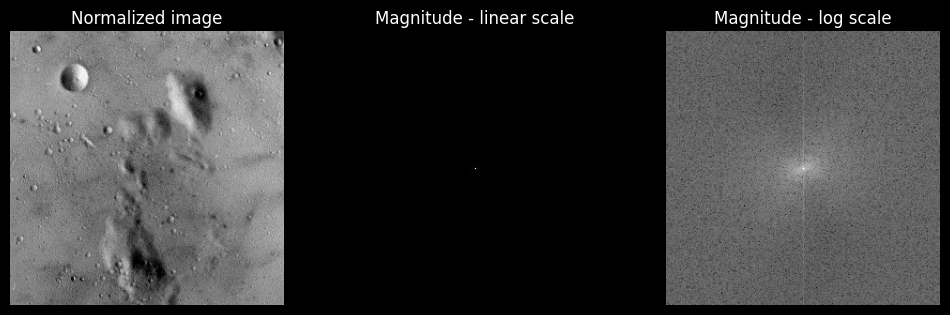

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


def dft_2d(image):
    image = np.asarray(image, dtype=np.complex128)

    temp = np.fft.fft(image, axis=1)  # DFT ανά γραμμή
    F = np.fft.fft(temp, axis=0)      # DFT ανά στήλη

    return F


# Διάβασμα εικόνας σε grayscale
img = cv2.imread("./images/Ασκηση 1/moon.jpg", cv2.IMREAD_GRAYSCALE)
print("Initial dynamic range:", np.min(img), np.max(img))

# Γραμμικός μετασχηματισμός δυναμικής περιοχής στο [0, 255]
img_norm = cv2.normalize(img, None, 0, 255, cv2.NORM_MINMAX)
print("New dynamic range:", np.min(img_norm), np.max(img_norm))

# Μεταφορά του σημείου (0,0) στο κέντρο
rows, cols = img_norm.shape
x = np.arange(rows).reshape(-1, 1)
y = np.arange(cols).reshape(1, -1)
centered_img = img_norm * ((-1) ** (x + y))

# Υπολογισμός 2D DFT
F = dft_2d(centered_img)

# Πλάτος μετασχηματισμού
magnitude = np.abs(F)

# Linear scale
magnitude_linear = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)

# Log scale
magnitude_log = np.log(1 + magnitude)
magnitude_log = cv2.normalize(magnitude_log, None, 0, 255, cv2.NORM_MINMAX)

# Απεικόνιση
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_norm, cmap="gray")
plt.title("Normalized image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(magnitude_linear, cmap="gray")
plt.title("Magnitude - linear scale")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(magnitude_log, cmap="gray")
plt.title("Magnitude - log scale")
plt.axis("off")

plt.show()

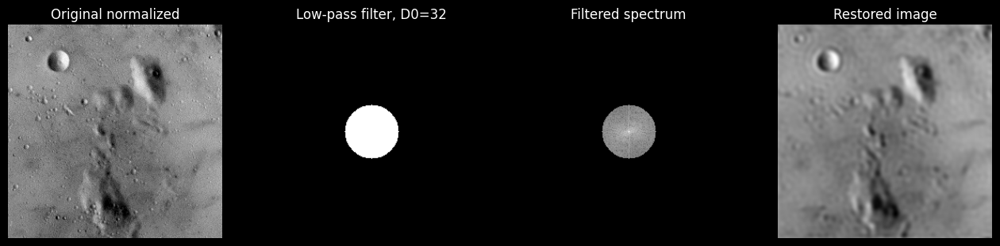

In [4]:
def ideal_lowpass_filter(shape, cutoff_radius):
    rows, cols = shape

    center_row = rows // 2
    center_col = cols // 2

    u = np.arange(rows).reshape(-1, 1)
    v = np.arange(cols).reshape(1, -1)

    distance = np.sqrt((u - center_row) ** 2 + (v - center_col) ** 2)

    H = np.zeros((rows, cols), dtype=np.float32)
    H[distance <= cutoff_radius] = 1

    return H


def idft_2d(F):
    F = np.asarray(F, dtype=np.complex128)
    # 1D IDFT ανά γραμμή
    temp = np.fft.ifft(F, axis=1)
    # 1D IDFT ανά στήλη
    image = np.fft.ifft(temp, axis=0)
    return image


# Δημιουργία low-pass φίλτρου
cutoff_radius = min(rows, cols) // 8
H = ideal_lowpass_filter(F.shape, cutoff_radius)
# Εφαρμογή φίλτρου στο πεδίο συχνοτήτων
G = F * H
# IDFT με μέθοδο γραμμών-στηλών
img_back = idft_2d(G)
# Κρατάμε το πραγματικό μέρος
img_back = np.real(img_back)
# Επαναφορά από το κεντραρισμένο πεδίο στο κανονικό πεδίο χώρου
restored = img_back * ((-1) ** (x + y))
# Κανονικοποίηση για εμφάνιση
restored_display = cv2.normalize(restored, None, 0, 255, cv2.NORM_MINMAX)

# Φάσμα μετά το φίλτρο
filtered_magnitude = np.abs(G)
filtered_magnitude_log = np.log(1 + filtered_magnitude)
filtered_magnitude_log = cv2.normalize(filtered_magnitude_log, None, 0, 255, cv2.NORM_MINMAX)

plt.figure(figsize=(16, 4))

plt.subplot(1, 4, 1)
plt.imshow(img_norm, cmap="gray")
plt.title("Original normalized")
plt.axis("off")

plt.subplot(1, 4, 2)
plt.imshow(H, cmap="gray")
plt.title(f"Low-pass filter, D0={cutoff_radius}")
plt.axis("off")

plt.subplot(1, 4, 3)
plt.imshow(filtered_magnitude_log, cmap="gray")
plt.title("Filtered spectrum")
plt.axis("off")

plt.subplot(1, 4, 4)
plt.imshow(restored_display, cmap="gray")
plt.title("Restored image")
plt.axis("off")

plt.show()

### Ερώτημα 2

Dynamic range: 0 255
Dynamic range: 0 255
Dynamic range: 0 255


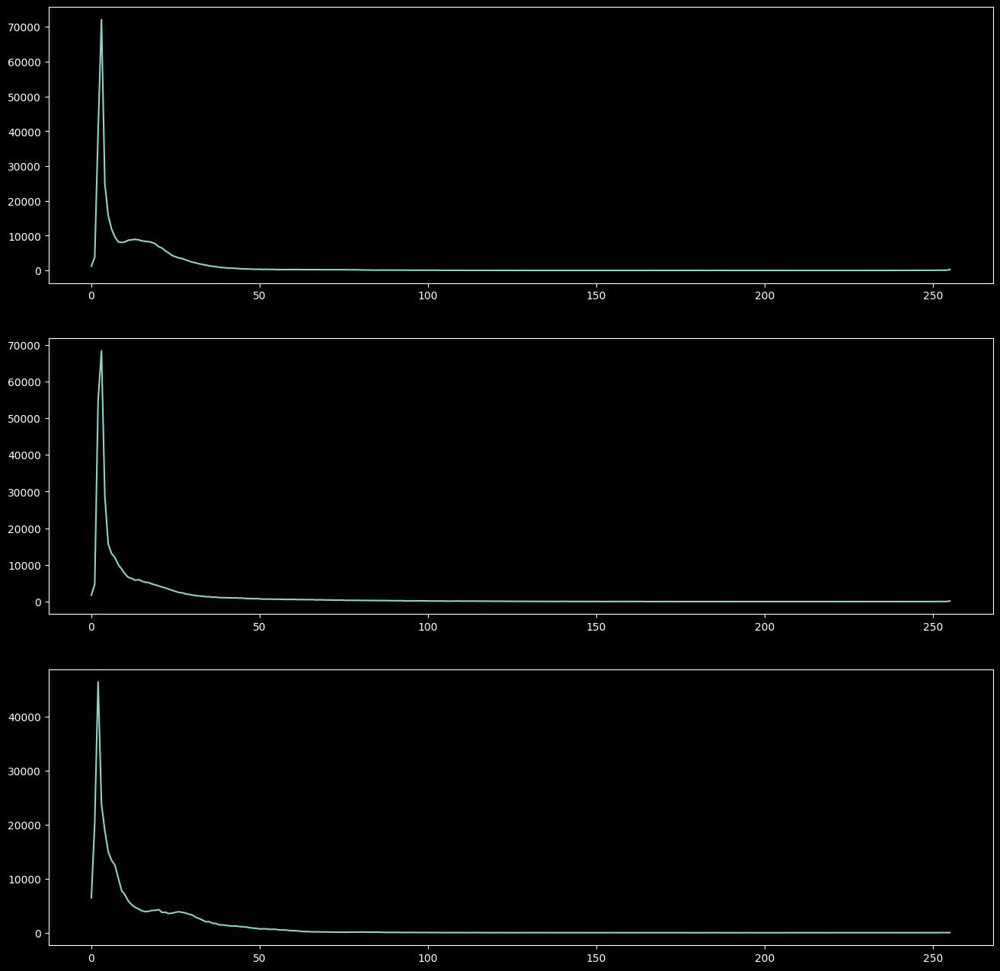

Dynamic range after equalization: 0 255
Dynamic range after equalization: 0 255
Dynamic range after equalization: 0 255


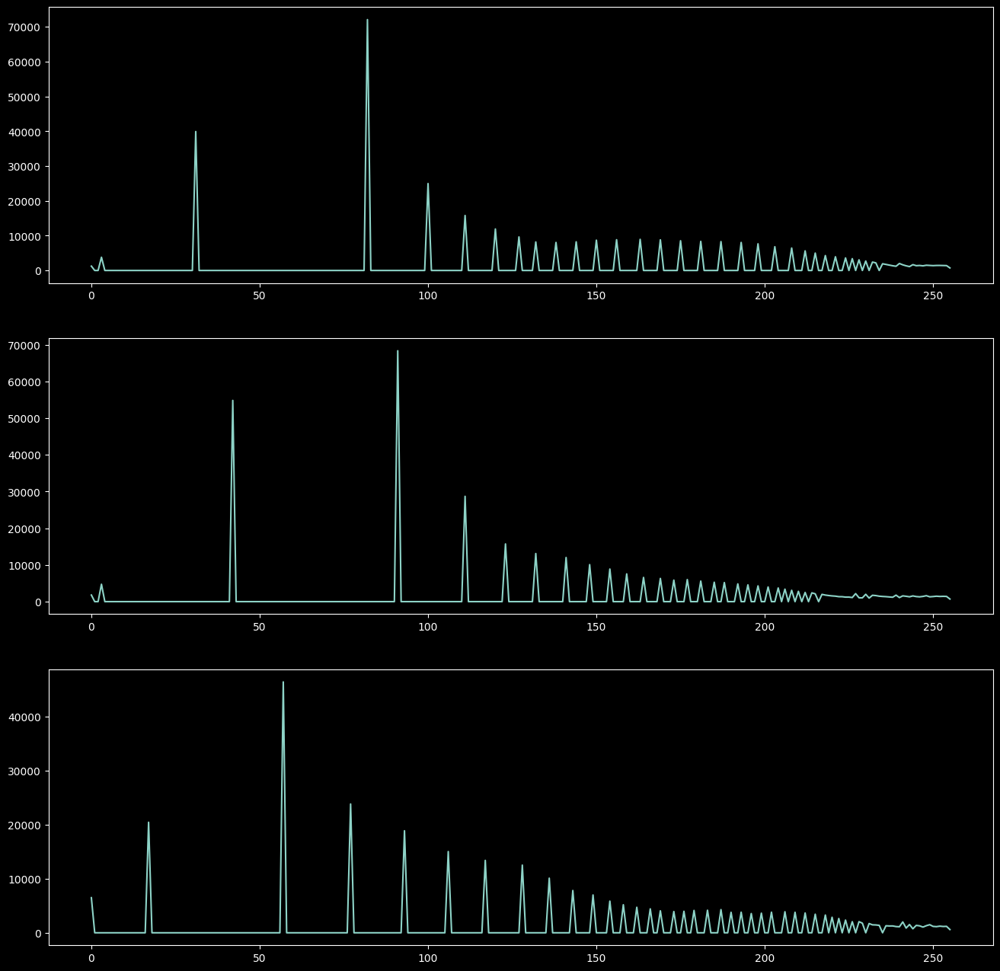

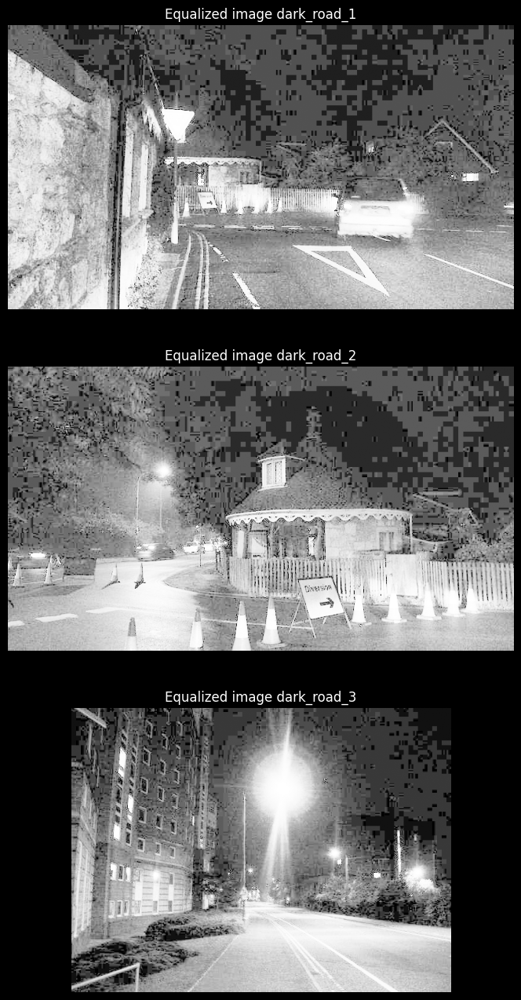

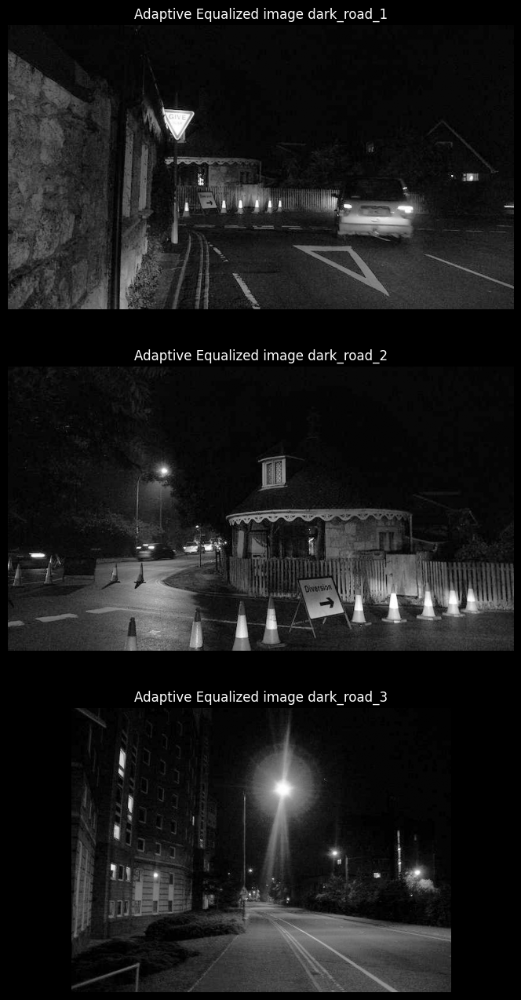

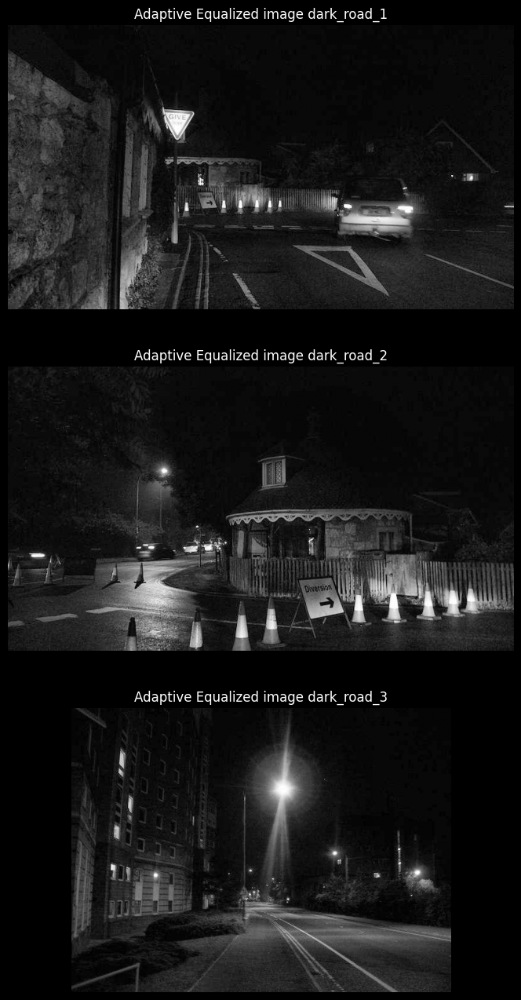

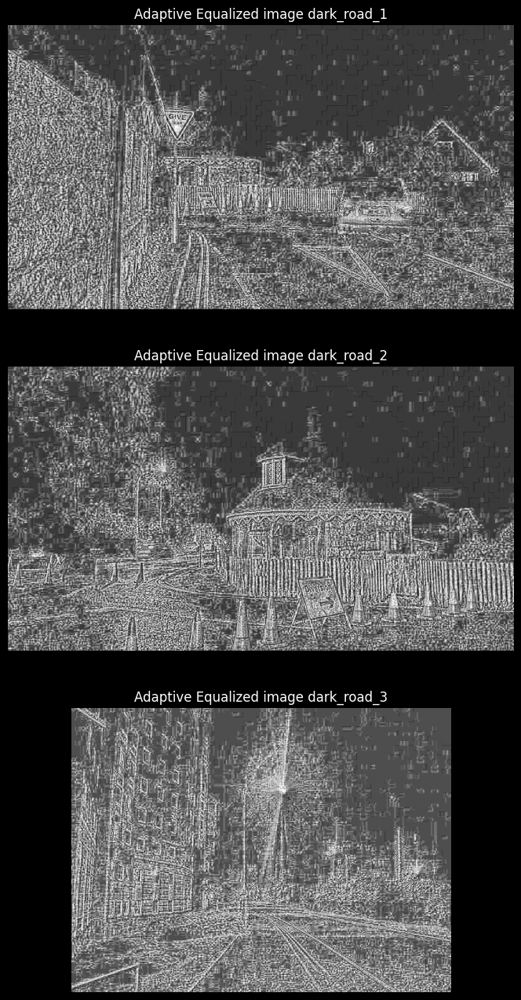

In [5]:
img1 = cv2.imread("./images/Ασκηση 2/dark_road_1.jpg", cv2.IMREAD_GRAYSCALE)
img2 = cv2.imread("./images/Ασκηση 2/dark_road_2.jpg", cv2.IMREAD_GRAYSCALE)
img3 = cv2.imread("./images/Ασκηση 2/dark_road_3.jpg", cv2.IMREAD_GRAYSCALE)
images = [img1, img2, img3]
titles = ["dark_road_1", "dark_road_2", "dark_road_3"]
plt.figure(figsize=(16, 16))

#παρουσίαση ιστογραμμάτων
for i in range(len(images)):
    print("Dynamic range:", np.min(images[i]), np.max(images[i]))
    hist = cv2.calcHist([images[i]], [0], None, [256], [0, 256])

    plt.subplot(len(images), 1, i + 1)
    plt.plot(hist)
    # plt.axis("off")
plt.show()

#εμφάνιση και ολική εξίσωση ιστογραμμάτων
plt.figure(figsize=(16, 16))
for i in range(len(images)):
    eq_img = cv2.equalizeHist(images[i])
    print("Dynamic range after equalization:", np.min(eq_img), np.max(eq_img))
    hist_eq = cv2.calcHist([eq_img], [0], None, [256], [0, 256])

    plt.subplot(len(images), 1, i + 1)
    plt.plot(hist_eq)
    # plt.axis("off")
plt.show()

#εμφάνιση εικόνων
equalized_images = []

plt.figure(figsize=(16, 16))
for i, img in enumerate(images):
    eq = cv2.equalizeHist(img)
    equalized_images.append(eq)
    plt.subplot(len(images), 1, i + 1)
    plt.imshow(eq, cmap="gray")
    plt.axis("off")
    plt.title(f"Equalized image {titles[i]}")
plt.show()

#τοπική εξίσωση ιστογράμματος
tile_sizes = [(1, 1), (8, 8), (256, 256)]

for i, size in enumerate(tile_sizes):
    plt.figure(figsize=(16, 16))
    for i, img in enumerate(images):
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=size)
        adaptive_eq = clahe.apply(img)
        plt.subplot(len(images), 1, i + 1)
        plt.imshow(adaptive_eq, cmap="gray")
        plt.axis("off")
        plt.title(f"Adaptive Equalized image {titles[i]}")
plt.show()

### Ερώτημα 3

MSE:  0.0 PSNR:  inf comparing original to Original image
MSE:  342.52374 PSNR:  22.783897 comparing original to Noisy image Gaussian
MSE:  4441.041 PSNR:  11.655955 comparing original to Noisy image impulse
MSE:  4858.4297 PSNR:  11.265844 comparing original to Final image
MSE:  430.99432 PSNR:  21.786089 comparing original to Denoised gaussian - moving avg - 3x3
MSE:  1129.3456 PSNR:  17.602535 comparing original to Denoised gaussian - moving avg - 5x5
MSE:  376.13727 PSNR:  22.37734 comparing original to Denoised gaussian - median - 3x3
MSE:  999.2998 PSNR:  18.133846 comparing original to Denoised gaussian - median - 5x5
MSE:  1191.7029 PSNR:  17.369123 comparing original to Denoised impulse - moving avg - 3x3
MSE:  1583.7765 PSNR:  16.133865 comparing original to Denoised impulse - moving avg - 5x5
MSE:  551.0864 PSNR:  20.718605 comparing original to Denoised impulse - median - 3x3
MSE:  1061.7861 PSNR:  17.870434 comparing original to Denoised impulse - median - 5x5
MSE:  774.01

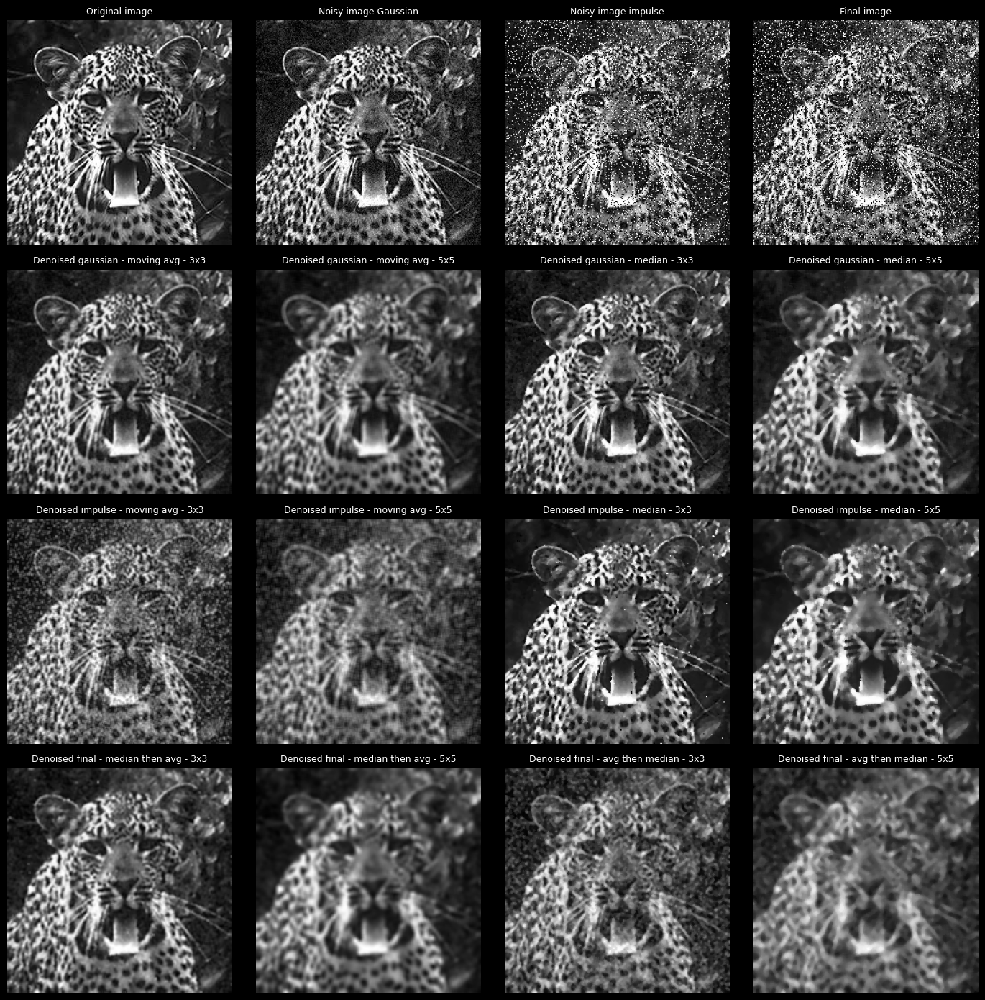

In [6]:
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt
import cv2

def add_gaussian_noise(signal, snr_db):
    signal = signal.astype(np.float32)
    signal_power = np.mean(signal ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear
    noise_std = np.sqrt(noise_power)
    noise = noise_std * np.random.randn(*signal.shape)
    noisy_signal = signal + noise
    noisy_signal = np.clip(noisy_signal, 0, 255)
    return noisy_signal.astype(np.uint8)

def add_impulse_noise(img, amount=0.2):
    noisy = img.copy()
    random_values = np.random.rand(*img.shape)
    noisy[random_values < amount/2] = 0
    noisy[random_values > 1 - amount/2] = 255
    return noisy

def metrics(original, denoised, title=""):
    original = original.astype(np.float32)
    denoised = denoised.astype(np.float32)


    mse = np.mean((original - denoised) ** 2)
    if mse == 0:
        psnr = float("inf")
    else:
        psnr = 10 * np.log10((255.0 ** 2) / mse)
    print("MSE: ", mse, "PSNR: ", psnr, "comparing original to", title)


#load the image
data = loadmat('./images/Ασκηση 3/tiger.mat')
x = data['tiger']
x = x.astype(np.float32)
# print(x)
image = (x*255).astype('uint8')

#add noise
noisy_img = add_gaussian_noise(image, 15)
noisy_img_impulse = add_impulse_noise(image)
final_noisy_img = add_impulse_noise(noisy_img)

#denoise with filters

moving_avg = lambda img, kernel_size = 3 : cv2.blur(img, (kernel_size, kernel_size))
denoised_median = lambda img, kernel_size = 3 : cv2.medianBlur(img, kernel_size)

kernel_sizes = [3, 5]
images = [image, noisy_img, noisy_img_impulse, final_noisy_img]
titles = ["Original image", "Noisy image Gaussian", "Noisy image impulse", "Final image"]

# Denoise Gaussian noisy image
for k in kernel_sizes:
    images.append(moving_avg(noisy_img, k))
    titles.append(f"Denoised gaussian - moving avg - {k}x{k}")

for k in kernel_sizes:
    images.append(denoised_median(noisy_img, k))
    titles.append(f"Denoised gaussian - median - {k}x{k}")

# Denoise impulse noisy image
for k in kernel_sizes:
    images.append(moving_avg(noisy_img_impulse, k))
    titles.append(f"Denoised impulse - moving avg - {k}x{k}")

for k in kernel_sizes:
    images.append(denoised_median(noisy_img_impulse, k))
    titles.append(f"Denoised impulse - median - {k}x{k}")

# Denoise final noisy image with combined filters
for k in kernel_sizes:
    result = moving_avg(denoised_median(final_noisy_img, k), k)
    images.append(result)
    titles.append(f"Denoised final - median then avg - {k}x{k}")

for k in kernel_sizes:
    result = denoised_median(moving_avg(final_noisy_img, k), k)
    images.append(result)
    titles.append(f"Denoised final - avg then median - {k}x{k}")

# Plot
plt.figure(figsize=(14, 14))

for i, im in enumerate(images):
    plt.subplot(4, 4, i + 1)
    plt.imshow(im, cmap="gray")
    plt.title(titles[i], fontsize=9)
    plt.axis("off")
    metrics(image, im, titles[i])

plt.tight_layout()
plt.show()

### Ερώτημα 4
Μέρος Α

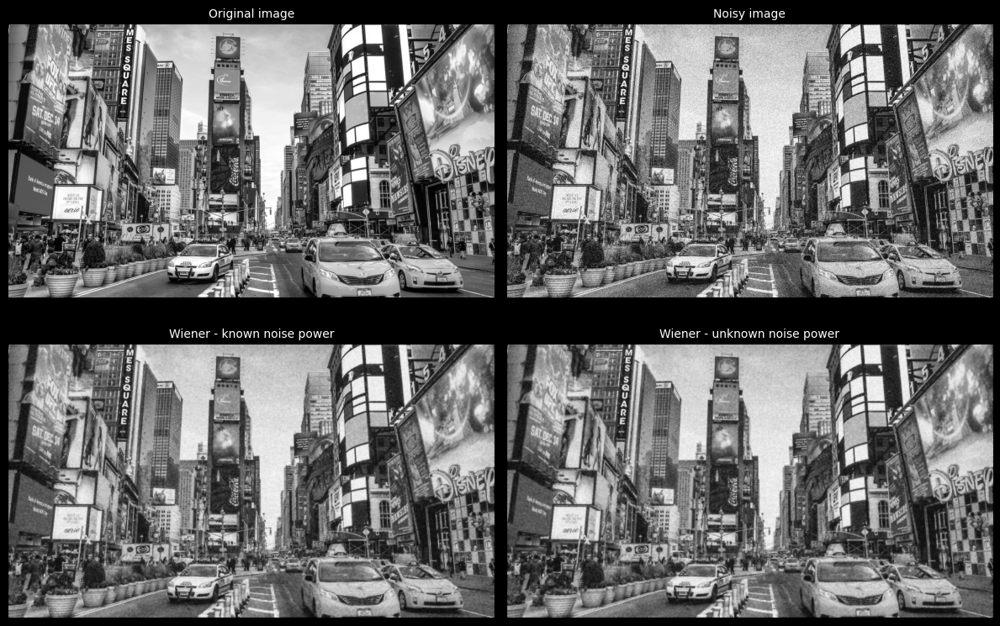

In [7]:
from scipy.signal import wiener


def get_noisy_image_noisy_power(signal, snr_db):
    signal = signal.astype(np.float32)
    signal_power = np.mean(signal ** 2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear
    noise_std = np.sqrt(noise_power)
    noise = noise_std * np.random.randn(*signal.shape)
    noisy_signal = signal + noise
    noisy_signal = np.clip(noisy_signal, 0, 255)
    return noisy_signal.astype(np.uint8), noise_power


image = cv2.imread("./images/Ασκηση 4/new_york.png", cv2.IMREAD_GRAYSCALE)
snr = 10 #in db
noisy_image, noise_power = get_noisy_image_noisy_power(image, snr)
window_size = 7

wiener_known_noise = wiener(
    noisy_image.astype(np.float32),
    mysize=(window_size, window_size),
    noise=noise_power
)
wiener_unknown_noise = wiener(
    noisy_image.astype(np.float32),
    mysize=(window_size, window_size)
)

images = [image, noisy_image, wiener_known_noise, wiener_unknown_noise]
titles = ["Original image", "Noisy image", "Wiener - known noise power", "Wiener - unknown noise power"]

plt.figure(figsize=(12, 8))
for i, im in enumerate(images):
    plt.subplot(2, 2, i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.axis("off")
    plt.title(titles[i], fontsize=10)
plt.tight_layout()
plt.show()

### Ερώτημα 4
Μέρος Β

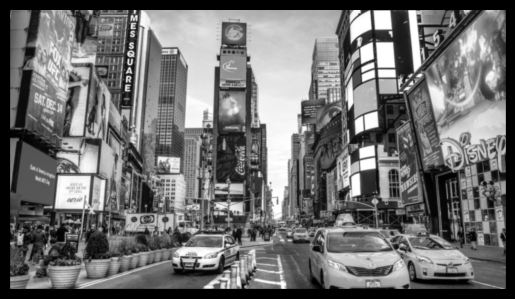

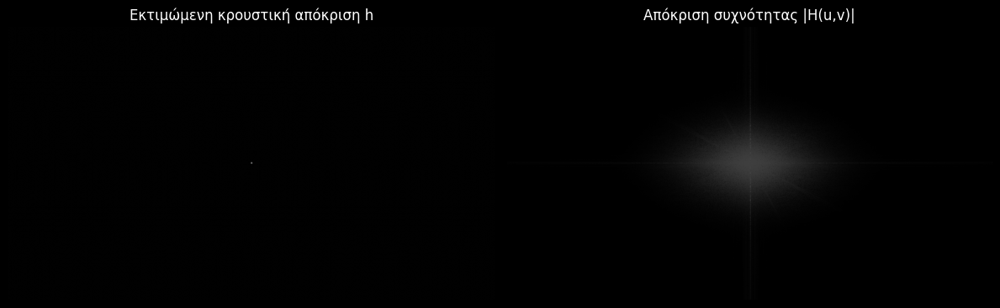

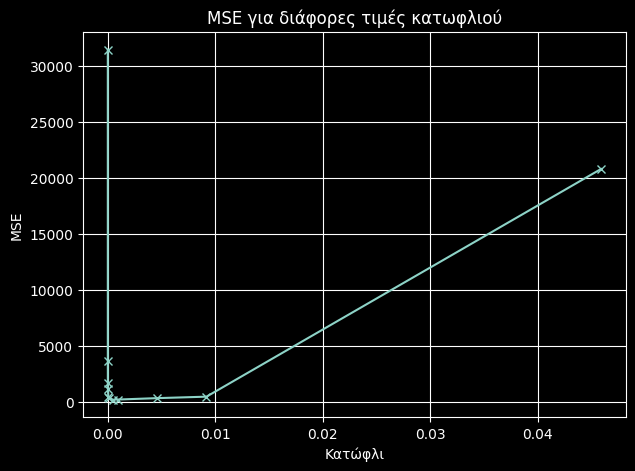

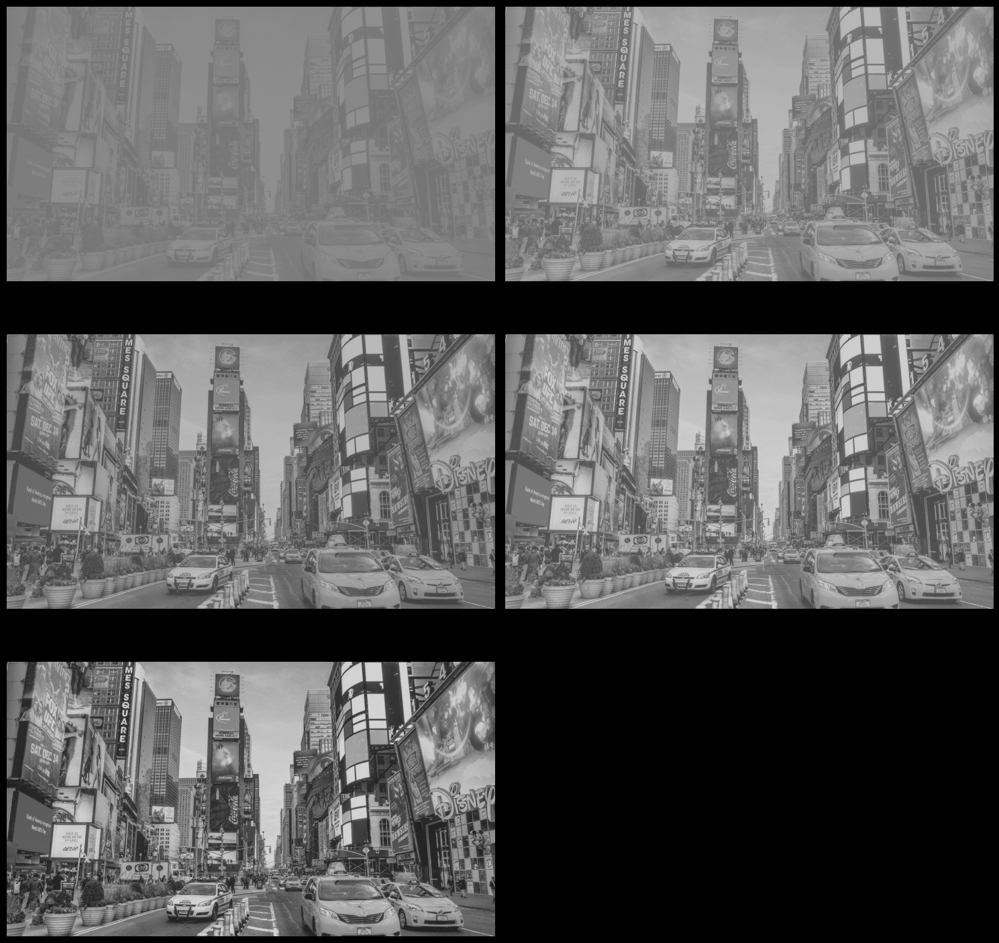

In [8]:
from scipy.io import loadmat
import matplotlib.pyplot as plt

def inverse_filter(Y, H, threshold):
    Y = np.float32(Y)
    F_Y_local = np.fft.fft2(Y)
    H_abs = np.abs(H)
    H_inv = np.zeros_like(H, dtype=np.complex128)
    mask = H_abs > threshold
    H_inv[mask] = 1 / H[mask]
    F_X_hat = F_Y_local * H_inv
    X_hat = np.fft.ifft2(F_X_hat)
    X_hat = np.real(X_hat)
    return X_hat

data = loadmat("result.mat")
Y = data["Y"]
X = image.astype(np.float32)

Y = np.squeeze(Y).astype(np.float32)
X = np.squeeze(X).astype(np.float32)

if X.max() <= 1:
    X = X * 255

if Y.max() <= 1:
    Y = Y * 255

plt.imshow(Y, cmap="gray")
plt.axis("off")
plt.show()

#υπολογισμός κρουστικής απόκρισης
F_X = np.fft.fft2(X)
F_Y = np.fft.fft2(Y)
eps = 1e-8 * np.max(np.abs(F_X)**2)

H = (F_Y * np.conj(F_X)) / (np.abs(F_X)**2 + eps)
h = np.fft.ifft2(H)
h = np.real(h)
h_shifted = np.fft.fftshift(h)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.imshow(h_shifted, cmap="gray")
plt.title("Εκτιμώμενη κρουστική απόκριση h")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(H))), cmap="gray")
plt.title("Απόκριση συχνότητας |H(u,v)|")
plt.axis("off")
plt.tight_layout()
plt.show()

#Αντιστροφή και υπολογισμός για κατώφλια
max_H = np.max(np.abs(H))
thresholds_rel = np.array([0, 1e-5, 5e-5, 1e-4, 5e-4, 1e-3, 5e-3, 1e-2, 5e-2, 1e-1, 5e-1])
thresholds = thresholds_rel * max_H
mse_values = []
restored_images = []

for t in thresholds:
    X_hat = inverse_filter(Y, H, t)
    mse = np.mean((X-X_hat)**2)
    mse_values.append(mse)
    restored_images.append(X_hat)
mse_values = np.array(mse_values)

plt.figure(figsize=(7, 5))
plt.plot(thresholds , mse_values, marker="x")
plt.xlabel("Κατώφλι")
plt.ylabel("MSE")
plt.title("MSE για διάφορες τιμές κατωφλιού")
plt.grid(True)
plt.show()

indices_to_show = [0, 2, 4, 6, 8]
plt.figure(figsize=(15, 15))
for i, idx in enumerate(indices_to_show):
    plt.subplot(3, 2, i + 1)
    plt.imshow(restored_images[idx], cmap="gray")
    plt.axis("off")
plt.tight_layout()
plt.show()

### Ερώτημα 5

r = 5% | MSE Zonal = 31.30 | MSE Threshold = 17.14
r = 10% | MSE Zonal = 16.40 | MSE Threshold = 8.50
r = 15% | MSE Zonal = 11.92 | MSE Threshold = 5.09
r = 20% | MSE Zonal = 8.66 | MSE Threshold = 3.25
r = 25% | MSE Zonal = 6.13 | MSE Threshold = 2.12
r = 30% | MSE Zonal = 5.09 | MSE Threshold = 1.42
r = 35% | MSE Zonal = 4.18 | MSE Threshold = 0.96
r = 40% | MSE Zonal = 2.74 | MSE Threshold = 0.64
r = 45% | MSE Zonal = 2.32 | MSE Threshold = 0.43
r = 50% | MSE Zonal = 1.86 | MSE Threshold = 0.27


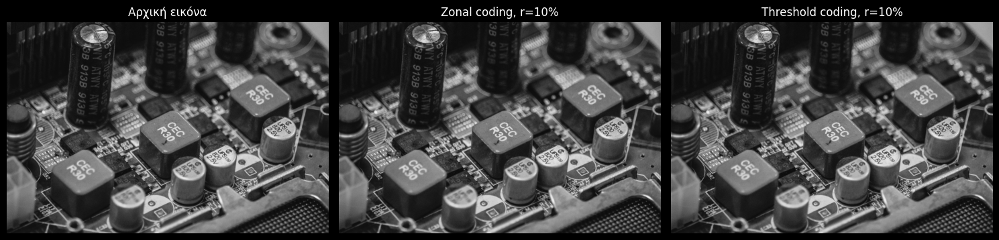

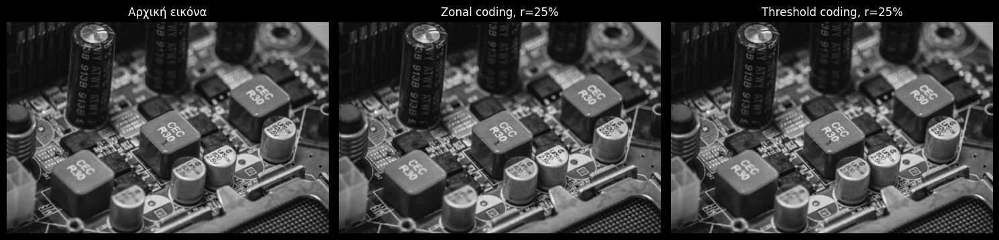

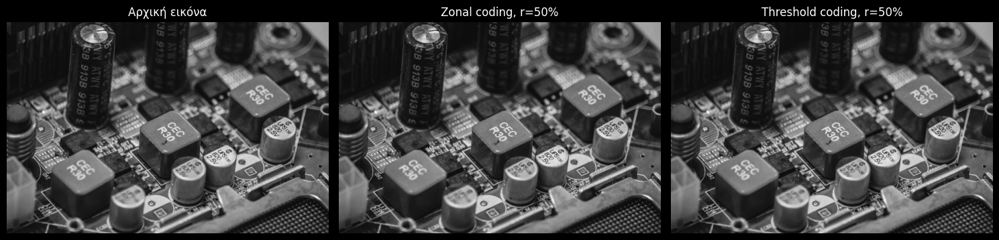

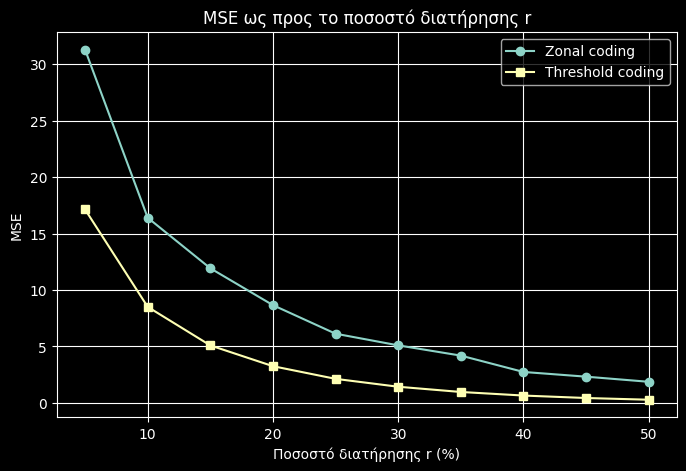

In [9]:
image = cv2.imread("./images/Ασκηση 5/board.png", cv2.IMREAD_GRAYSCALE)
image = np.float32(image)
block_size = 32
h, w = image.shape
h = (h // block_size) * block_size
w = (w // block_size) * block_size
image_cropped = image[:h, :w]

def calculate_mse(original, reconstructed):
    return np.mean((original - reconstructed) ** 2)


def dct_zonal_reconstruction(image, block_size, r):
    h, w = image.shape
    reconstructed = np.zeros_like(image)
    k = int(np.sqrt(r) * block_size)
    k = max(1, k)

    for i in range(0, h, block_size):
        for j in range(0, w, block_size):
            block = image[i:i + block_size, j:j + block_size]
            dct_block = cv2.dct(block)
            dct_compressed = np.zeros_like(dct_block)
            dct_compressed[:k, :k] = dct_block[:k, :k]
            reconstructed_block = cv2.idct(dct_compressed)
            reconstructed[i:i + block_size, j:j + block_size] = reconstructed_block
    return np.clip(reconstructed, 0, 255)


def dct_threshold_reconstruction(image, block_size, r):
    h, w = image.shape
    reconstructed = np.zeros_like(image)
    cutoff_point = max(1, int(r * block_size * block_size))

    for i in range(0, h, block_size):
        for j in range(0, w, block_size):

            block = image[i:i + block_size, j:j + block_size]
            dct_block = cv2.dct(block)
            # Απόλυτες τιμές όλων των συντελεστών
            abs_dct_values_to_keep = np.abs(dct_block).flatten()
            # Κατώφλι ώστε να κρατήσουμε περίπου num_keep συντελεστές
            threshold = np.sort(abs_dct_values_to_keep)[-cutoff_point]
            # Κρατάμε όσους συντελεστές έχουν απόλυτη τιμή >= threshold
            dct_compressed = np.where(np.abs(dct_block) >= threshold, dct_block, 0)
            reconstructed_block = cv2.idct(dct_compressed)
            reconstructed[i:i + block_size, j:j + block_size] = reconstructed_block
    reconstructed = np.clip(reconstructed, 0, 255)
    return reconstructed


r_values = np.arange(0.05, 0.55, 0.05)
selected_r = [0.10, 0.25, 0.50]
mse_zonal = []
mse_threshold = []
zonal_results = {}
threshold_results = {}

for r in r_values:
    rec_zonal = dct_zonal_reconstruction(image_cropped, block_size, r)
    rec_threshold = dct_threshold_reconstruction(image_cropped, block_size, r)
    mse_z = calculate_mse(image_cropped, rec_zonal)
    mse_t = calculate_mse(image_cropped, rec_threshold)
    mse_zonal.append(mse_z)
    mse_threshold.append(mse_t)
    zonal_results[r] = rec_zonal
    threshold_results[r] = rec_threshold
    print(
        f"r = {r * 100:.0f}% | "
        f"MSE Zonal = {mse_z:.2f} | "
        f"MSE Threshold = {mse_t:.2f}"
    )

for r in selected_r:
    plt.figure(figsize=(15, 5))
    plt.subplot(1, 3, 1)
    plt.imshow(image_cropped, cmap="gray", vmin=0, vmax=255)
    plt.title("Αρχική εικόνα")
    plt.axis("off")
    plt.subplot(1, 3, 2)
    plt.imshow(zonal_results[r], cmap="gray", vmin=0, vmax=255)
    plt.title(f"Zonal coding, r={int(r * 100)}%")
    plt.axis("off")
    plt.subplot(1, 3, 3)
    plt.imshow(threshold_results[r], cmap="gray", vmin=0, vmax=255)
    plt.title(f"Threshold coding, r={int(r * 100)}%")
    plt.axis("off")

    plt.tight_layout()
    plt.show()


plt.figure(figsize=(8, 5))
plt.plot(r_values * 100, mse_zonal, marker="o", label="Zonal coding")
plt.plot(r_values * 100, mse_threshold, marker="s", label="Threshold coding")
plt.xlabel("Ποσοστό διατήρησης r (%)")
plt.ylabel("MSE")
plt.title("MSE ως προς το ποσοστό διατήρησης r")
plt.grid(True)
plt.legend()
plt.show()

### Ερώτημα 6

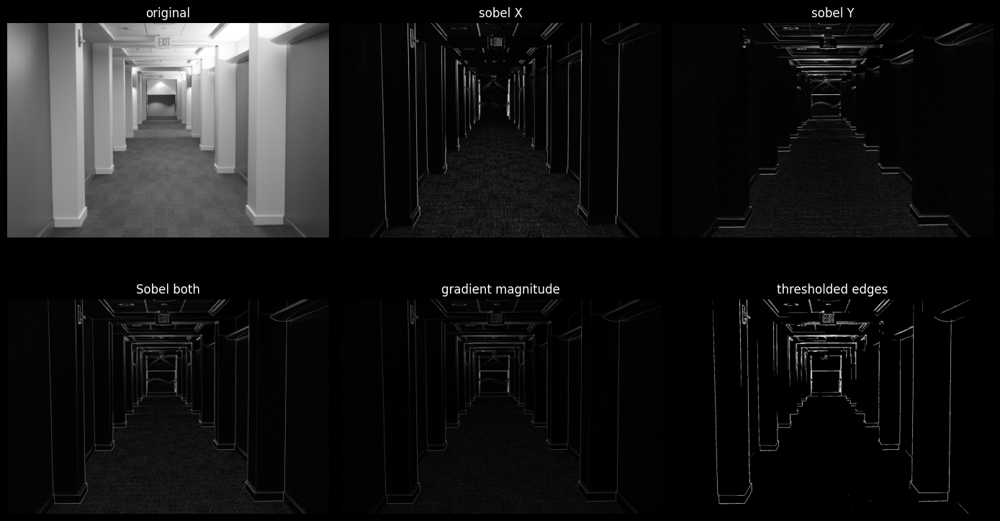

In [25]:
image = cv2.imread("./images/Ασκηση 6/hallway.png", cv2.IMREAD_GRAYSCALE)

sobel_x = cv2.Sobel(image, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(image, cv2.CV_64F, 0, 1, ksize=3)
sobel_x_abs = cv2.convertScaleAbs(sobel_x)
sobel_y_abs = cv2.convertScaleAbs(sobel_y)
sobel = cv2.addWeighted(sobel_x_abs, 0.5, sobel_y_abs, 0.5, 0)

#Gradient magnitude
gradient_magnitude = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
gradient_magnitude_norm = cv2.normalize(
    gradient_magnitude, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

#Threshold
threshold_value = np.percentile(gradient_magnitude_norm, 98)
_, edges_threshold = cv2.threshold((gradient_magnitude_norm), threshold_value, 255, cv2.THRESH_BINARY)
edges_threshold = edges_threshold.astype(np.uint8)

titles = ['original', 'sobel X', 'sobel Y', 'Sobel both', 'gradient magnitude', 'thresholded edges']
images = [image, sobel_x_abs, sobel_y_abs, sobel, gradient_magnitude_norm, edges_threshold]

plt.figure(figsize=(14, 10))
for i, im in enumerate(images):
    plt.subplot(2, 3, i + 1)
    plt.imshow(im, cmap="gray", vmin=0, vmax=255)
    plt.title(titles[i])
    plt.axis("off")
    plt.tight_layout()
plt.show()

Lines detected: 66


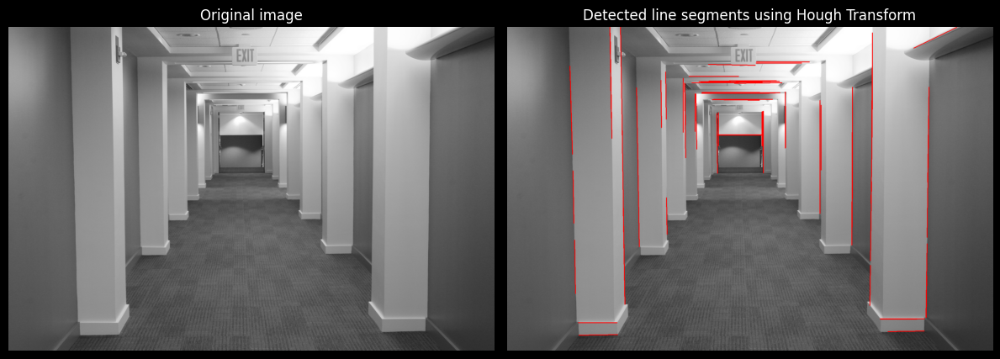

In [37]:
lines = cv2.HoughLinesP(
    edges_threshold,
    rho=1,
    theta=np.pi / 180,
    threshold=120,
    minLineLength=120,
    maxLineGap=10
)
image_color = cv2.imread("./images/Ασκηση 6/hallway.png", cv2.IMREAD_COLOR)
hough_result = image_color.copy()

if lines is not None:
    for line in lines:
        x1, y1, x2, y2 = line[0]
        cv2.line(
            hough_result, (x1, y1),(x2, y2), (0, 0, 255), 2) # red in BGR

print("Lines detected:", 0 if lines is None else len(lines))

# Convert BGR to RGB for correct display with matplotlib
original_rgb = cv2.cvtColor(image_color, cv2.COLOR_BGR2RGB)
hough_result_rgb = cv2.cvtColor(hough_result, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(12, 6))
plt.subplot(1, 2, 1)
plt.imshow(original_rgb)
plt.title("Original image")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(hough_result_rgb)
plt.title("Detected line segments using Hough Transform")
plt.axis("off")
plt.tight_layout()
plt.show()